# 03-1. 관측값 추정: 후보 모델과 교차검증

도로기상 미관측 지점의 관측값을 추정하는 모델을 학습하고 검증 지점에서 평가한다(03).
이 노트북은 1~2장으로, 학습/검증 지점을 나누고 후보 방법을 지점 단위 교차검증으로 비교해 기본 방법(앙상블)을 고른다.
기본 앙상블은 03-2의 3-6에서 새 RWIS 노면온도 보간(B3)을 더해 최종 방법으로 확정한다.

03 구성: **03-1 후보 모델·교차검증(1~2장)** · 03-2 추가 실험·RWIS 보간 개선(3장) · 03-3 검증 지점 평가·시각화·저장(4~6장)

- 검증 지점(학습 제외): 부곡교 12410, 삼봉 33411, 해전 23402
- 평가 지표: BIAS, MAE, RMSE

검증 지점은 모두 목표(결빙) 관측소라서 노면상태와 **노면온도**만 관측한다(01-2의 3-2 참고). 따라서 추정 대상은 노면온도이다.
노면온도는 결빙 판단의 핵심 변수이고, 04의 결빙 분류와 05의 구간별 위험도에 입력으로 쓰인다.

- 입력: 02-2의 지점 변수 (`data/processed/station_features.parquet`)
- 출력: 교차검증 예측·설정 (`data/processed/estimation_oof.parquet`, `estimation_cv.json`, 03-2·03-3에서 사용), 교차검증 성능 (`data/results/estimation_cv_scores.csv`)

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parents[1]  # notebooks/<단계 폴더>/ 에서 실행
sys.path.insert(0, str(ROOT))

from src import config

In [2]:
import json
import time
import warnings

import geopandas as gpd
import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from cycler import cycler
from matplotlib import font_manager
from scipy.spatial.distance import cdist
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)

for font in ["NanumGothic", "Malgun Gothic", "AppleGothic"]:
    if any(f.name == font for f in font_manager.fontManager.ttflist):
        plt.rcParams["font.family"] = font
        break
plt.rcParams.update({
    "axes.unicode_minus": False,
    "axes.prop_cycle": cycler(color=["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
                                     "#e87ba4", "#008300", "#4a3aa7", "#e34948"]),
    "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.6,
    "axes.edgecolor": "#c3c2b7", "axes.spines.top": False, "axes.spines.right": False,
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "figure.dpi": 100, "lines.linewidth": 1.5,
})

for d in [config.RESULT_DIR, config.MODEL_DIR, config.FIGURE_DIR]:
    d.mkdir(parents=True, exist_ok=True)

SEED = 42
TARGET = "rst"  # 노면온도

In [3]:
sf = pd.read_parquet(config.PROCESSED_DIR / "station_features.parquet")
stations = pd.read_parquet(config.PROCESSED_DIR / "stations.parquet").set_index("stn")
meta = json.load(open(config.PROCESSED_DIR / "features.json", encoding="utf-8"))
FEATURES = meta["features"]
print(sf.shape, f"변수 {len(FEATURES)}개")
for group, cols in meta["groups"].items():
    print(f"  {group}: {', '.join(cols)}")

(587520, 47) 변수 40개
  기상: ta, td, rh, dpd, ws, rain, pr60, pr12h, pr_day, cloud, tg, snow, sunshine, ta_d1h, ta_d3h, ta_min12h, rh_mean3h, rain_hrs12h, hrs_since_rain
  주변도로기상: nbr_rst, nbr_anom, rst_phys, nbr_ice, nbr_ice_3h, nbr_wet, nbr_snow, nbr_dist
  시간·일사: hour_sin, hour_cos, sun_elev, season_day, sunlit, solar_eff
  지형: elev, tpi, relief, shade_winter, dist_river
  도로: dist_bridge, dist_tunnel


## 1. 학습/검증 데이터 분리

검증 지점 3곳은 학습에서 완전히 뺀다. 02-2에서 만든 주변 RWIS 변수도 학습 지점 14곳만 원천으로 썼으므로
검증 지점의 관측값은 어떤 형태로도 학습에 들어가지 않는다.

In [4]:
def split_holdout(df):
    """검증 지점(config.HOLDOUT_STATIONS)을 학습 데이터에서 분리한다."""
    is_holdout = df["stn"].isin(config.HOLDOUT_STATIONS)
    return df[~is_holdout].reset_index(drop=True), df[is_holdout].reset_index(drop=True)


train_all, holdout = split_holdout(sf)
train = train_all.dropna(subset=[TARGET])
print(f"학습 지점 {train_all['stn'].nunique()}곳: {train.shape[0]:,}행 (노면온도 결측 제외)")
print(f"검증 지점 {holdout['stn'].nunique()}곳: {holdout[TARGET].notna().sum():,}행")
pd.DataFrame({stn: {"지점명": name, "노선": route} for stn, (name, route) in config.HOLDOUT_STATIONS.items()}).T

학습 지점 14곳: 479,843행 (노면온도 결측 제외)
검증 지점 3곳: 103,677행


,지점명,노선
12410,부곡교,서해안
33411,삼봉,통영-대전중부선
23402,해전,호남선


## 2. 모델 구성 및 학습

### 검증 방식

학습 지점 14곳을 2곳씩 7묶음으로 나눈 **지점 단위 교차검증**을 한다. 한 묶음의 지점은 학습에 쓰지 않은 채 예측하므로
미관측 지점 추정과 같은 조건이다. 성능은 지점별 RMSE의 평균으로 비교하고,
**최종 방법은 교차검증 성능으로만 고른다** (검증 지점 3곳은 마지막 평가에만 쓴다).

**묶음 누수 방지.** 02-2의 주변 RWIS 변수(`nbr_rst`, `rst_phys` 등)는 학습 지점 14곳을 모두 원천으로 만들었다. 이 변수를 그대로 쓰면
학습 지점의 변수 안에 검증 묶음 지점의 관측이 들어간다. 그래서 묶음마다 원천을 나머지 학습 지점 12곳으로 바꿔 주변 RWIS 변수를 다시 만든다
(02-2의 3-3과 같은 방법). 학습에 쓰는 지점은 자기 자신을 뺀 11곳, 검증 지점은 12곳이 원천이다.
최종 모델(학습 지점 14곳의 자기 자신 제외 변수로 학습 → 14곳을 원천으로 한 검증 지점·구간 변수로 추정)과 같은 구조이다.

### 후보

| 이름 | 방법 | 입력 |
|------|------|------|
| B0 보간 기온 | 노면온도 = 보간 기온, 학습 없음 (노면 에너지 수지를 무시한 가장 단순한 근사, 비교 기준) | `ta` |
| B1 주변 노면온도 | 가까운 RWIS 3곳 노면온도 IDW (고도 보정), 학습 없음 | `nbr_rst` |
| B2 기온+노면편차 | 보간 기온 + 주변 RWIS (노면온도-기온) 편차 IDW, 학습 없음 | `rst_phys` |
| LightGBM(전체) | 그래디언트 부스팅 | 02-2의 변수 전체 |
| LightGBM(핵심) | 그래디언트 부스팅, 작은 트리 | 핵심 변수 |
| Ridge(핵심) | 선형 회귀 (L2 규제) | 핵심 변수 |
| 앙상블 | LightGBM(핵심), Ridge(핵심), B1의 단순 평균 | |

03-2의 3-6에서 이 앙상블에 B3(AWS·ASOS 밑그림 + RWIS 그날의 오차 크리깅)를 더해 최종 방법을 정한다.

핵심 변수는 지점이 바뀌어도 관계가 유지될 만한 것으로 골랐다: 주변 RWIS 노면온도, 보간 기온·지면온도·이슬점·습도·풍속·운량·일조,
태양고도와 지형 그늘. 표고·교량 거리 같은 **정적 변수는 학습 지점이 14곳뿐이라 사실상 지점 식별자 역할**을 하므로 핵심 변수에서 뺐다.

In [5]:
CORE = ["nbr_rst", "rst_phys", "ta", "tg", "td", "rh", "ws", "cloud", "sunshine",
        "sun_elev", "sunlit", "solar_eff"]
N_FOLDS = 7
LGB_PARAMS = {
    "LightGBM(전체)": dict(objective="regression", learning_rate=0.05, n_estimators=1000, num_leaves=63,
                         min_child_samples=200, subsample=0.7, subsample_freq=1, colsample_bytree=0.7,
                         reg_lambda=1.0, random_state=SEED, n_jobs=-1, verbose=-1),
    "LightGBM(핵심)": dict(objective="regression", learning_rate=0.03, n_estimators=600, num_leaves=15,
                         min_child_samples=5000, subsample=0.7, subsample_freq=1, colsample_bytree=0.7,
                         reg_lambda=5.0, random_state=SEED, n_jobs=-1, verbose=-1),
}
LGB_FEATURES = {"LightGBM(전체)": FEATURES, "LightGBM(핵심)": CORE}


def make_ridge():
    return make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), Ridge(alpha=1.0))


def station_folds(stns, n_folds):
    """지점을 n_folds 묶음으로 나눈다 (번호순으로 번갈아 배정해 노선이 섞이게 한다)."""
    stns = sorted(stns)
    return [stns[i::n_folds] for i in range(n_folds)]


folds = station_folds(train_all["stn"].unique(), N_FOLDS)
print("교차검증 묶음:", folds)

교차검증 묶음: [[np.int64(12103), np.int64(23204)], [np.int64(12209), np.int64(23403)], [np.int64(12210), np.int64(33103)], [np.int64(12211), np.int64(33206)], [np.int64(12409), np.int64(33409)], [np.int64(23202), np.int64(33410)], [np.int64(23203), np.int64(33412)]]


In [6]:
# 묶음 누수 방지: 주변 RWIS 변수를 원천 지점에 맞춰 다시 만든다 (02-2의 3-2·3-3과 같은 방법)
WET_STATES = [2, 3, 4, 11, 12, 13, 14, 15]  # 젖은 노면 상태 (02-2의 3-3과 같음)
NBR_FEATURES = ["nbr_rst", "nbr_anom", "rst_phys", "nbr_ice", "nbr_ice_3h", "nbr_wet", "nbr_snow", "nbr_dist"]
_g = gpd.GeoSeries(gpd.points_from_xy(stations["lon"], stations["lat"]), crs=4326).to_crs(5179)
STN_XY = pd.DataFrame({"x": _g.x.to_numpy(), "y": _g.y.to_numpy()}, index=stations.index)
TRAIN_STNS = sorted(train_all["stn"].unique())
N_T = len(train_all) // len(TRAIN_STNS)
assert (train_all["stn"].to_numpy() == np.repeat(TRAIN_STNS, N_T)).all()
PERIOD_ID = np.searchsorted([pd.Timestamp(s) for s, _ in config.PERIODS[1:]], train_all["time"].iloc[:N_T].to_numpy(),
                            side="right")
_wide = lambda col: train_all[col].to_numpy("float32").reshape(len(TRAIN_STNS), N_T)
_state = _wide("state")
NBR_SRC = {"rst": _wide("rst"), "ta": _wide("ta"),
           "ice": np.where(np.isnan(_state), np.nan, np.isin(_state, config.ICE_STATE_CODES)).astype("float32"),
           "wet": np.where(np.isnan(_state), np.nan, np.isin(_state, WET_STATES)).astype("float32"),
           "snow": np.where(np.isnan(_state), np.nan, _state == 3).astype("float32")}


def idw_weights(tgt_xy, src_xy, k=3, power=2, exclude=None):
    """(대상 x 원천) IDW 가중치. exclude[i]=j 이면 대상 i에서 원천 j를 뺀다 (02-2의 3-2와 같음)."""
    d = cdist(tgt_xy, src_xy)
    if exclude is not None:
        for i, j in enumerate(exclude):
            if j >= 0:
                d[i, j] = np.inf
    w = np.zeros_like(d)
    nearest = np.argsort(d, axis=1)[:, :k]
    rows = np.arange(len(d))[:, None]
    w[rows, nearest] = 1.0 / np.maximum(d[rows, nearest], 50.0) ** power
    return w.astype("float32")


def idw_apply(w, values):
    """values: (원천 x 시각). 결측 원천은 그 시각 가중치에서 빠진다 (02-2의 3-2와 같음)."""
    ok = ~np.isnan(values)
    num = w @ np.where(ok, values, 0)
    den = w @ ok.astype("float32")
    with np.errstate(invalid="ignore", divide="ignore"):
        return np.where(den > 0, num / den, np.nan).astype("float32")


def neighbor_features(src_stns):
    """학습 지점 14곳의 주변 RWIS 변수를 원천 src_stns만으로 다시 만든다. 원천인 지점은 자기 자신을 뺀다.

    반환: train_all과 같은 행 순서의 DataFrame (NBR_FEATURES).
    """
    src = [TRAIN_STNS.index(s) for s in src_stns]
    exclude = [src.index(i) if i in src else -1 for i in range(len(TRAIN_STNS))]
    tgt_xy, src_xy = STN_XY.loc[TRAIN_STNS].to_numpy(), STN_XY.loc[list(src_stns)].to_numpy()
    w = idw_weights(tgt_xy, src_xy, exclude=exclude)
    elev, lapse = stations.loc[TRAIN_STNS, "elev"].to_numpy("float32"), np.float32(0.0065)
    f = {"nbr_rst": idw_apply(w, NBR_SRC["rst"][src] + lapse * elev[src, None]) - lapse * elev[:, None],
         "nbr_anom": idw_apply(w, NBR_SRC["rst"][src] - NBR_SRC["ta"][src])}
    f["rst_phys"] = NBR_SRC["ta"] + f["nbr_anom"]
    for v in ["ice", "wet", "snow"]:
        f[f"nbr_{v}"] = idw_apply(w, NBR_SRC[v][src])
    f["nbr_ice_3h"] = np.concatenate([pd.DataFrame(f["nbr_ice"][:, PERIOD_ID == p].T).rolling(18, min_periods=1).max()
                                      .to_numpy("float32").T for p in np.unique(PERIOD_ID)], axis=1)
    d = cdist(tgt_xy, src_xy)
    for i, j in enumerate(exclude):
        if j >= 0:
            d[i, j] = np.inf
    f["nbr_dist"] = np.repeat((d.min(axis=1) / 1000)[:, None], N_T, axis=1).astype("float32")
    return pd.DataFrame({c: f[c].ravel() for c in NBR_FEATURES}, index=train_all.index)


FOLD_NBR = [neighbor_features([s for s in TRAIN_STNS if s not in v]) for v in folds]


def fold_frame(k):
    """k번째 묶음을 검증할 때 쓰는 train_all. 주변 RWIS 변수만 그 묶음의 학습 지점 원천으로 바뀐다."""
    return train_all.assign(**FOLD_NBR[k])


# 원천을 학습 지점 14곳 전체로 하면 02-2의 변수와 같아야 한다
check = neighbor_features(TRAIN_STNS)
print("02-2 주변 RWIS 변수와의 최대 차이:", float(np.nanmax(np.abs(check.to_numpy() - train_all[NBR_FEATURES].to_numpy()))))
for k in range(len(folds)):  # 묶음별로 숨긴 지점의 관측이 들어가 있던 학습 지점 수
    chg = (FOLD_NBR[k]["nbr_rst"] - train_all["nbr_rst"]).abs()[~train_all["stn"].isin(folds[k])]
    by_stn = chg.groupby(train_all["stn"]).max()
    print(f"묶음 {k + 1} {folds[k]}: 학습 지점 12곳 중 {int((by_stn > 0).sum())}곳의 주변 노면온도가 바뀜 "
          f"(바뀐 값의 평균 |변화| {chg[chg > 0].mean():.2f}°C)")

02-2 주변 RWIS 변수와의 최대 차이: 0.0
묶음 1 [np.int64(12103), np.int64(23204)]: 학습 지점 12곳 중 6곳의 주변 노면온도가 바뀜 (바뀐 값의 평균 |변화| 0.44°C)
묶음 2 [np.int64(12209), np.int64(23403)]: 학습 지점 12곳 중 6곳의 주변 노면온도가 바뀜 (바뀐 값의 평균 |변화| 0.36°C)
묶음 3 [np.int64(12210), np.int64(33103)]: 학습 지점 12곳 중 8곳의 주변 노면온도가 바뀜 (바뀐 값의 평균 |변화| 0.37°C)
묶음 4 [np.int64(12211), np.int64(33206)]: 학습 지점 12곳 중 6곳의 주변 노면온도가 바뀜 (바뀐 값의 평균 |변화| 0.43°C)
묶음 5 [np.int64(12409), np.int64(33409)]: 학습 지점 12곳 중 6곳의 주변 노면온도가 바뀜 (바뀐 값의 평균 |변화| 0.70°C)
묶음 6 [np.int64(23202), np.int64(33410)]: 학습 지점 12곳 중 5곳의 주변 노면온도가 바뀜 (바뀐 값의 평균 |변화| 0.41°C)
묶음 7 [np.int64(23203), np.int64(33412)]: 학습 지점 12곳 중 4곳의 주변 노면온도가 바뀜 (바뀐 값의 평균 |변화| 0.37°C)


모든 후보는 묶음마다 다시 만든 주변 RWIS 변수로 학습·예측한다 (B1·B2도 이 변수에서 가져온다).
LightGBM은 묶음마다 검증 곡선을 기록하고, 곡선 평균이 가장 낮은 반복 횟수를 고른다.

In [7]:
oof = pd.DataFrame(index=train_all.index)
oof["B0 보간 기온"] = train_all["ta"]
for k, val_stns in enumerate(folds):
    rows = train_all["stn"].isin(val_stns)
    oof.loc[rows, "B1 주변 노면온도"] = FOLD_NBR[k].loc[rows, "nbr_rst"]
    oof.loc[rows, "B2 기온+노면편차"] = FOLD_NBR[k].loc[rows, "rst_phys"]
best_iter, fold_models = {}, {}

for name, params in LGB_PARAMS.items():
    feats, curves, models = LGB_FEATURES[name], [], []
    t0 = time.time()
    for k, val_stns in enumerate(folds):
        f = fold_frame(k).dropna(subset=[TARGET])
        tr, va = f[~f["stn"].isin(val_stns)], f[f["stn"].isin(val_stns)]
        record = {}
        m = lgb.LGBMRegressor(**params)
        m.fit(tr[feats], tr[TARGET], eval_set=[(va[feats], va[TARGET])], eval_metric="rmse",
              callbacks=[lgb.record_evaluation(record)])
        curves.append(record["valid_0"]["rmse"])
        models.append(m)
    mean_curve = np.mean(curves, axis=0)
    best_iter[name] = int(np.argmin(mean_curve)) + 1
    fold_models[name] = (models, mean_curve)
    pred = pd.Series(np.nan, index=train_all.index)
    for k, (m, val_stns) in enumerate(zip(models, folds)):
        rows = train_all["stn"].isin(val_stns)
        pred[rows] = m.predict(fold_frame(k).loc[rows, feats], num_iteration=best_iter[name])
    oof[name] = pred
    print(f"{name}: 최적 반복 {best_iter[name]}회 ({time.time() - t0:.0f}s)")

pred = pd.Series(np.nan, index=train_all.index)
for k, val_stns in enumerate(folds):
    f = fold_frame(k)
    rows = f["stn"].isin(val_stns)
    tr = f[~rows].dropna(subset=[TARGET])
    pred[rows] = make_ridge().fit(tr[CORE], tr[TARGET]).predict(f.loc[rows, CORE])
oof["Ridge(핵심)"] = pred
ENSEMBLE = ["LightGBM(핵심)", "Ridge(핵심)", "B1 주변 노면온도"]
oof["앙상블"] = oof[ENSEMBLE].mean(axis=1)

LightGBM(전체): 최적 반복 78회 (410s)


LightGBM(핵심): 최적 반복 529회 (59s)


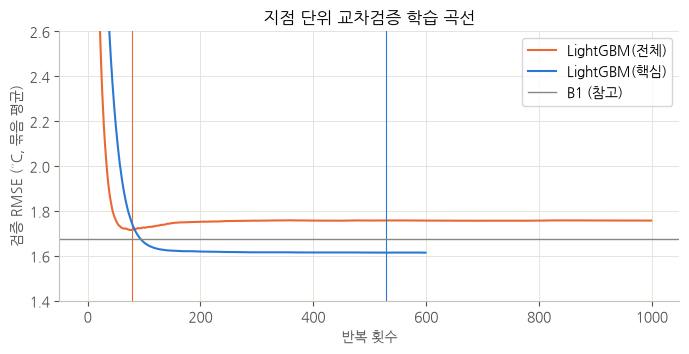

In [8]:
fig, ax = plt.subplots(figsize=(8, 3.5))
for name, color in zip(LGB_PARAMS, ["#eb6834", "#2a78d6"]):
    curve = fold_models[name][1]
    ax.plot(curve, color=color, label=name)
    ax.axvline(best_iter[name], color=color, linewidth=0.8)
ax.axhline(np.sqrt((oof["B1 주변 노면온도"] - train_all[TARGET]).pow(2).mean()), color="#898781",
           linewidth=1, label="B1 (참고)")
ax.set_xlabel("반복 횟수")
ax.set_ylabel("검증 RMSE (°C, 묶음 평균)")
ax.set_ylim(1.4, 2.6)
ax.set_title("지점 단위 교차검증 학습 곡선")
ax.legend()
plt.show()

변수 전체를 쓴 LightGBM은 몇십 번 반복 만에 검증 오차가 다시 커진다. 학습 지점의 고유한 특성(센서 위치, 포장, 주변 그늘 등)을
외워 버리고, 처음 보는 지점에는 일반화하지 못하는 것이다. 작은 트리와 핵심 변수만 쓴 모델은 이 문제가 덜하다.

In [9]:
def regression_scores(y_true, y_pred):
    """관측값 추정 성능 {"N", "BIAS", "MAE", "RMSE"}. BIAS = 평균(추정 - 관측)."""
    y_true, y_pred = np.asarray(y_true, float), np.asarray(y_pred, float)
    ok = ~(np.isnan(y_true) | np.isnan(y_pred))
    err = y_pred[ok] - y_true[ok]
    return {"N": int(ok.sum()), "BIAS": err.mean(), "MAE": np.abs(err).mean(), "RMSE": np.sqrt((err ** 2).mean())}


def score_table(df, preds):
    """지점별 성능 + 지점 평균 행."""
    rows = []
    for method in preds.columns:
        for stn, idx in df.groupby("stn").groups.items():
            rows.append({"stn": stn, "지점명": stations.loc[stn, "name"], "방법": method,
                         **regression_scores(df.loc[idx, TARGET], preds.loc[idx, method])})
    scores = pd.DataFrame(rows)
    mean = scores.groupby("방법", sort=False)[["N", "BIAS", "MAE", "RMSE"]].mean().reset_index()
    mean.insert(0, "지점명", f"{df['stn'].nunique()}개 지점 평균")
    mean.insert(0, "stn", "mean")
    return pd.concat([scores, mean], ignore_index=True)


cv_scores = score_table(train_all, oof)
cv_summary = cv_scores[cv_scores["stn"] == "mean"].set_index("방법")[["BIAS", "MAE", "RMSE"]]
cv_summary.sort_values("RMSE").round(3)

,BIAS,MAE,RMSE
방법,,,
앙상블,-0.010,1.107,1.556
Ridge(핵심),0.037,1.131,1.573
LightGBM(핵심),-0.002,1.134,1.582
B1 주변 노면온도,-0.066,1.161,1.642
LightGBM(전체),-0.069,1.233,1.697
B2 기온+노면편차,-0.058,1.319,1.824
B0 보간 기온,-1.995,2.398,3.120


In [10]:
MODEL_CANDIDATES = ["LightGBM(전체)", "LightGBM(핵심)", "Ridge(핵심)", "앙상블"]
FINAL = cv_summary.loc[MODEL_CANDIDATES, "RMSE"].idxmin()
print(f"2절 기본 방법: {FINAL} (교차검증 RMSE {cv_summary.loc[FINAL, 'RMSE']:.3f}, "
      f"B1 {cv_summary.loc['B1 주변 노면온도', 'RMSE']:.3f})")

2절 기본 방법: 앙상블 (교차검증 RMSE 1.556, B1 1.642)


**묶음 누수를 막은 효과.** 02-2의 주변 RWIS 변수를 그대로 쓴 이전 교차검증에서는 앙상블 1.597, Ridge(핵심) 1.612, LightGBM(핵심) 1.649, LightGBM(전체) 1.755°C였다. 묶음마다 원천을 다시 만들자 모델 후보가 모두 0.04~0.07°C 좋아졌다. 누수가 점수를 부풀린 것이 아니라 오히려 나쁘게 보이게 했다. 학습 지점의 변수에 숨긴 지점의 관측이 섞여 있어서, 학습할 때의 주변 RWIS 변수가 실제로 추정할 때(미관측 지점)와 다른 조건이었기 때문이다. B1·B2는 그대로이다. 같은 묶음의 두 지점은 서로 멀어서, 서로의 가까운 3곳에 들지 않는다. 기본 방법은 그대로 앙상블이다.

지점별 교차검증 RMSE. 지점마다 편차가 크다. 서해안선 북부(군산휴·서김제·우곡3교)와 덕유산휴는 주변 관측소와 낮 시간 노면온도 차이가 커서
오차가 크다(약 1.8~2.4°C). 01-3의 4-2에서 본 것처럼 서김제는 낮 최고 노면온도가 다른 지점보다 크게 낮다.

In [11]:
cv_scores.pivot(index=["stn", "지점명"], columns="방법", values="RMSE")[list(oof.columns)].round(2)

,방법,B0 보간 기온,B1 주변 노면온도,B2 기온+노면편차,LightGBM(전체),LightGBM(핵심),Ridge(핵심),앙상블
stn,지점명,,,,,,,
12103,군산휴(도),2.90,2.16,2.16,2.00,1.84,1.81,1.90
12209,서김제(도),2.02,2.23,2.23,2.32,2.58,2.47,2.41
12210,부안고려청자휴(도),3.09,1.61,1.87,1.30,1.41,1.45,1.46
12211,고인돌휴(도),2.21,1.59,2.13,1.83,1.67,1.55,1.57
12409,우곡3교(도),1.99,2.08,2.08,1.70,1.94,1.93,1.95
23202,여산휴(도),3.86,1.28,1.88,1.92,1.34,1.40,1.29
23203,삼례졸음(도),3.18,1.62,1.68,1.77,1.40,1.48,1.46
23204,정읍휴(도),2.64,1.10,1.35,1.39,1.17,1.18,1.12
23403,호남터널(도),2.96,1.39,1.71,1.28,1.30,1.27,1.28


시간대와 대기 안정도에 따라 교차검증 오차가 어떻게 달라지는지 본다. 노면온도의 지점 간 차이는 낮에는 일사·그늘이,
밤에는 대기가 안정할수록 국지 지형이 만든다 (Chapman et al. 2001, 01-1의 0-3, 01-7의 13-5). 안정도는 지점별 보간 풍속·운량으로
Pasquill–Gifford 등급(D 바람·구름 많음 ~ G 고요)을 매긴다.

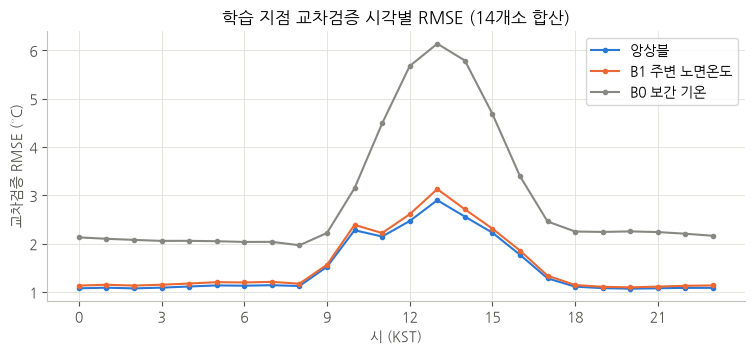

,밤 시간 비율,앙상블,B1 주변 노면온도,B0 보간 기온
D,0.080,0.943,0.991,1.947
E,0.138,1.091,1.130,2.146
F,0.071,1.192,1.218,2.281
G,0.712,1.099,1.156,2.141


In [12]:
def rmse(e):
    return np.sqrt((e ** 2).mean())


err = pd.DataFrame({name: oof[name] - train_all[TARGET] for name in [FINAL, "B1 주변 노면온도", "B0 보간 기온"]})
hour = train_all["time"].dt.hour
ws, octa = train_all["ws"], train_all["cloud"] * 0.8
stability = pd.Series(np.select([ws > 5, (ws >= 3) & (octa >= 4), ws >= 3, (ws >= 2) & (octa >= 4), ws >= 2, ws < 2],
                                ["D", "D", "E", "E", "F", "G"], "?"), index=train_all.index)
night = ((hour >= 19) | (hour <= 6)) & (stability != "?")
fig, ax = plt.subplots(figsize=(9, 3.5))
for name, color in zip(err.columns, ["#2a78d6", "#eb6834", "#898781"]):
    ax.plot(range(24), err.groupby(hour)[name].agg(rmse), marker="o", markersize=3, color=color, label=name)
ax.set_xticks(range(0, 24, 3))
ax.set_xlabel("시 (KST)")
ax.set_ylabel("교차검증 RMSE (°C)")
ax.set_title("학습 지점 교차검증 시각별 RMSE (14개소 합산)")
ax.legend()
plt.show()
by_class = err[night].groupby(stability[night]).agg(rmse)
by_class.insert(0, "밤 시간 비율", stability[night].value_counts(normalize=True))
by_class.round(3)

- **B0(노면온도 = 보간 기온)는 RMSE 3.1°C, BIAS -2.0°C**로 가장 나쁘다. 낮에는 일사로 노면이 기온보다 훨씬 따뜻해(13시 RMSE 6°C 이상)
  기온만으로는 노면온도를 설명할 수 없다. 에너지 수지의 일사·복사 항을 반영하는 주변 노면온도(B1)와 모델이 필요한 이유이다.
- 모델 오차도 한낮(13시 약 3°C)에 가장 크고 밤에는 1.1°C 안팎이다.
- 밤 오차는 바람·구름이 많은 D 등급에서 가장 작고(0.94°C), 안정한 F·G 등급에서 커진다(1.10~1.19°C).
  대기가 안정할수록 지점마다 국지 요인(교량, 그늘, 냉기호)이 커진다는 Chapman et al.(2001)의 결론과 맞다.
  결빙이 주로 생기는 밤 가운데 맑고 고요한 밤의 추정이 더 불확실하다는 점을 05-1의 위험도 해석에서 고려한다.

## 저장

- `data/processed/estimation_oof.parquet`: 학습 지점 교차검증 예측 (2절 후보 7개) → 03-2·03-3에서 사용
- `data/processed/estimation_cv.json`: 핵심 변수, LightGBM 설정·최적 반복 횟수, 교차검증 묶음, 기본 앙상블 구성·방법 (최종 방법은 03-2의 3-6에서 확정)
- `data/results/estimation_cv_scores.csv`: 학습 지점 교차검증 성능 (지점별 + 지점 평균)

In [13]:
BASE_METHODS = list(oof.columns)  # 2절 후보 (03-3의 검증 지점 표에 쓴다)
oof.assign(stn=train_all["stn"], time=train_all["time"]).to_parquet(
    config.PROCESSED_DIR / "estimation_oof.parquet", index=False)
cv_info = {"target": TARGET, "core": CORE, "lgb_params": LGB_PARAMS, "best_iter": best_iter,
           "folds": [[int(s) for s in v] for v in folds], "ensemble": ENSEMBLE, "final": FINAL,
           "base_methods": BASE_METHODS}
with open(config.PROCESSED_DIR / "estimation_cv.json", "w", encoding="utf-8") as f:
    json.dump(cv_info, f, ensure_ascii=False, indent=2)
cv_scores.round(4).to_csv(config.RESULT_DIR / "estimation_cv_scores.csv", index=False, encoding="utf-8-sig")
print("저장 완료")

저장 완료
